# Day 05 — Social Media Sentiment Analyzer: analysis

Top-level public comments on 12 fixed data/AI YouTube videos, classified by sentiment with our own rule-based lexicon model and grouped into recurring themes. **Sentiment here is a model output, not ground truth** — the model is validated against 120 human-labelled comments in §Q3, and every sentiment number below carries that qualifier.

Window: 2025-11-09 → 2026-11-09 (12 months, applied after fetching — the API has no date filter). Source: YouTube Data API v3, fetched live 2026-11-09. Corpus: 12 videos, 12 channels, selected from Day 4's frame by comment volume (see `data/README.md`).

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = None


def _find_root(start=None):
    """Resolve the project root from this notebook's own location.

    Uses __file__ when present (test harness sets it to the notebook
    path); otherwise falls back to the working directory and walks up
    checking for data/processed/comments.csv. A copy executed outside
    the project fails with a clear FileNotFoundError.
    """
    if start is None:
        start = globals().get("__file__")
    here = Path(start).resolve().parent if start else Path.cwd()
    for candidate in [here, *here.parents]:
        if (candidate / "data" / "processed" / "comments.csv").exists():
            return candidate
    raise FileNotFoundError(
        "data/processed/comments.csv not found above the notebook location"
    )


PROJECT_ROOT = _find_root()
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from sentiment import evaluate_predictions, top_bigrams, top_words  # noqa: E402

PROCESSED = PROJECT_ROOT / "data" / "processed"
CHARTS = PROJECT_ROOT / "outputs" / "charts"
print("Project root:", PROJECT_ROOT)

Project root: /home/hatch/workspace/goals/60-day-data-ai-portfolio/day-05-social-media-sentiment-analyzer


In [2]:
comments = pd.read_csv(PROCESSED / "comments.csv")
source = json.loads((PROCESSED / "data_source.json").read_text())
labels = pd.read_csv(PROCESSED / "validation_labels.csv", dtype=str).fillna("")
print(f"Analysed comments: {len(comments):,}  |  Videos: {comments['video_id'].nunique()}  |  Months: {comments['month'].nunique()}")
print(f"Source: {source['source']}  |  Quota used: {source['quota_units_used']} units  |  Fetched: {source['comment_count_fetched']} threads")
print(f"Filters: {source['filters']}")
print(f"Validation labels: {len(labels)} human-labelled comments")
comments.head(3)

Analysed comments: 1,462  |  Videos: 12  |  Months: 13
Source: cache  |  Quota used: 0 units  |  Fetched: 1600 threads
Filters: {'fetched': 1600, 'duplicates': 0, 'owner': 10, 'empty': 0, 'outside_window': 108, 'non_latin': 20, 'analysed': 1462}
Validation labels: 120 human-labelled comments


,comment_id,video_id,video_title,channel_title,topic,author_display_name,text,published_at,month,like_count,total_reply_count,sentiment_score,sentiment,scored_words,themes,language_flag
0,UgwmiSaf529Ga87w4l94AaABAg,t2oOFs4WgI0,Beyond the Numbers: A Data Analyst Journey | A...,TEDx Talks,career,@CogniBoostAI,"Hi, who else is here from the Google analytics...",2025-11-09T13:15:36Z,2025-11,0,0,0.4588,positive,2,praise,latin
1,UgypW_-dgksFJiUaqr54AaABAg,t2oOFs4WgI0,Beyond the Numbers: A Data Analyst Journey | A...,TEDx Talks,career,@renzopinasco2206,JUst going to say that mayonaisse looked weird.,2025-11-12T00:16:36Z,2025-11,0,0,0.0000,neutral,0,other,latin
2,Ugxz8u_lCtB2pP8B19Z4AaABAg,t2oOFs4WgI0,Beyond the Numbers: A Data Analyst Journey | A...,TEDx Talks,career,@jaikris-eq3mo,"You are No.1 as far as I am concerned, it is a...",2025-11-12T10:30:50Z,2025-11,0,0,0.3612,positive,3,criticism,latin


## Q1 — How positive, neutral or negative are the comments, and is that changing over time?

Shares with sample sizes. Monthly cells with n < 30 are thin and are flagged on the chart. Note the confound: the video mix changes month to month (two videos contribute ~40% of the frame), so the monthly trend is not a pure time trend — it partly reflects *which* videos were active that month.

In [3]:
shares = comments["sentiment"].value_counts(normalize=True) * 100
counts = comments["sentiment"].value_counts()
for label in ("positive", "neutral", "negative"):
    print(f"{label:>9}: {shares[label]:5.1f}%  (n={counts[label]})")
print(f"Mean compound: {comments['sentiment_score'].mean():.4f}  |  "
      f"Median compound: {comments['sentiment_score'].median():.4f}")
no_signal = (comments["scored_words"] == 0).mean() * 100
print(f"Comments with 0 lexicon words matched: {no_signal:.1f}% "
      "— these are neutral by default, not by meaning")
print()
by_topic = (
    comments.groupby("topic")["sentiment"]
    .value_counts(normalize=True)
    .unstack(fill_value=0) * 100
)
by_topic["n"] = comments.groupby("topic").size()
by_topic.round(1)

 positive:  40.6%  (n=594)
  neutral:  52.6%  (n=769)
 negative:   6.8%  (n=99)
Mean compound: 0.1437  |  Median compound: 0.0000
Comments with 0 lexicon words matched: 55.3% — these are neutral by default, not by meaning



sentiment,negative,neutral,positive,n
topic,,,,
ai_ml,13.3,63.9,22.8,294
bi_viz,3.1,40.8,56.1,98
career,2.9,50.1,47.0,381
python,7.0,48.6,44.4,500
sql,5.8,56.6,37.6,189


In [4]:
monthly = (
    comments.groupby("month")["sentiment"]
    .value_counts(normalize=True)
    .unstack(fill_value=0) * 100
)
monthly["n"] = comments.groupby("month").size()
monthly = monthly[["positive", "neutral", "negative", "n"]]
monthly.round(1)

sentiment,positive,neutral,negative,n
month,,,,
2025-11,57.1,42.9,0.0,14
2025-12,48.8,46.3,4.9,41
2026-01,47.4,47.4,5.3,57
2026-02,48.7,41.0,10.3,39
2026-03,52.4,40.5,7.1,42
2026-04,44.2,53.5,2.3,43
2026-05,36.9,53.8,9.2,65
2026-06,39.1,54.0,6.9,87
2026-07,52.3,39.4,8.3,109


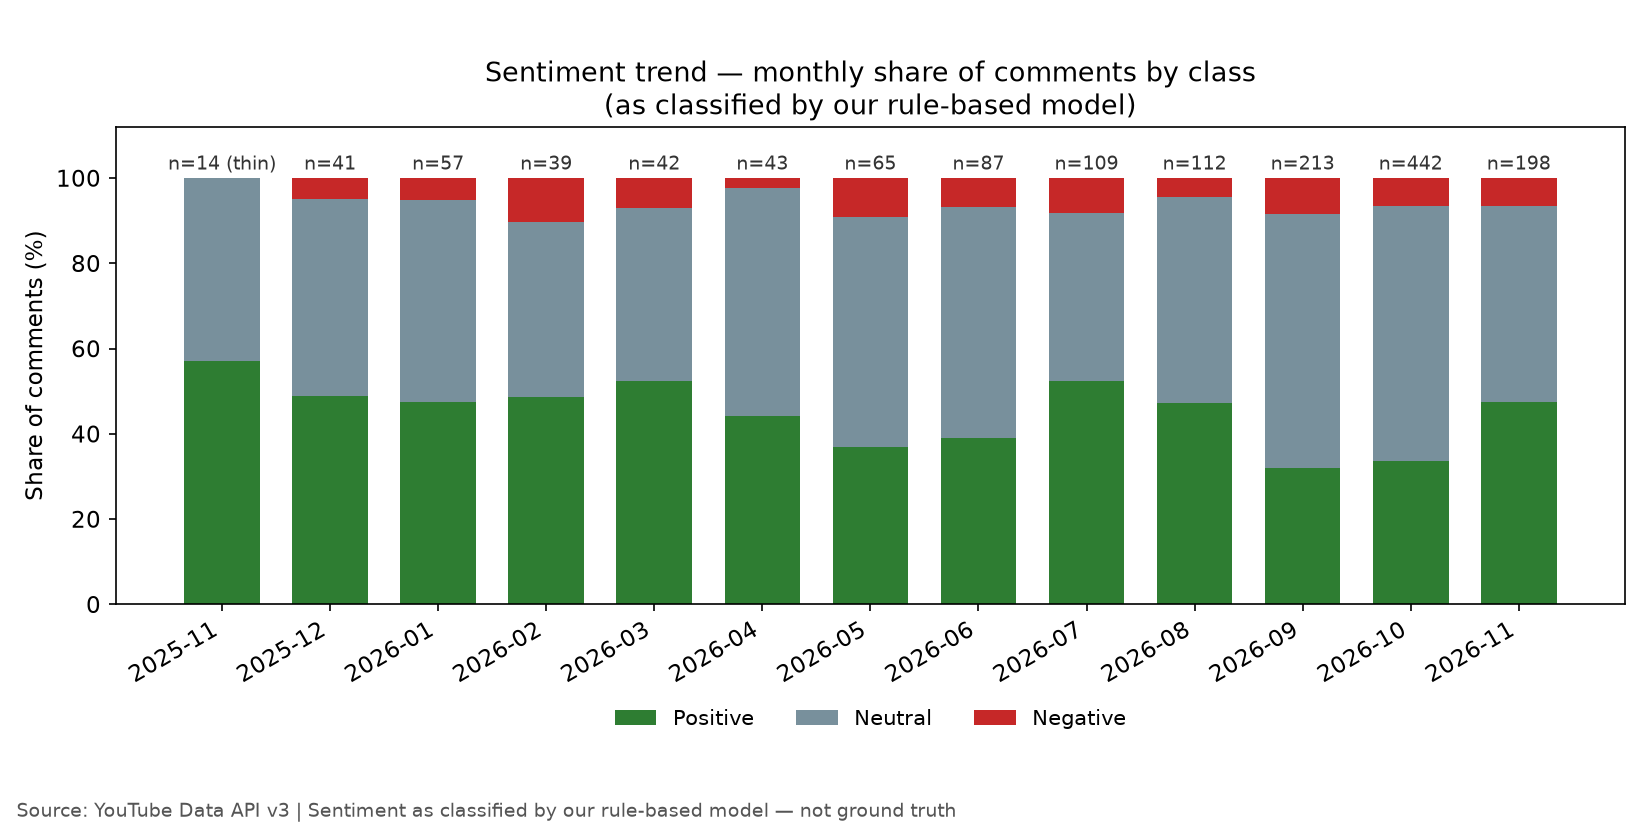

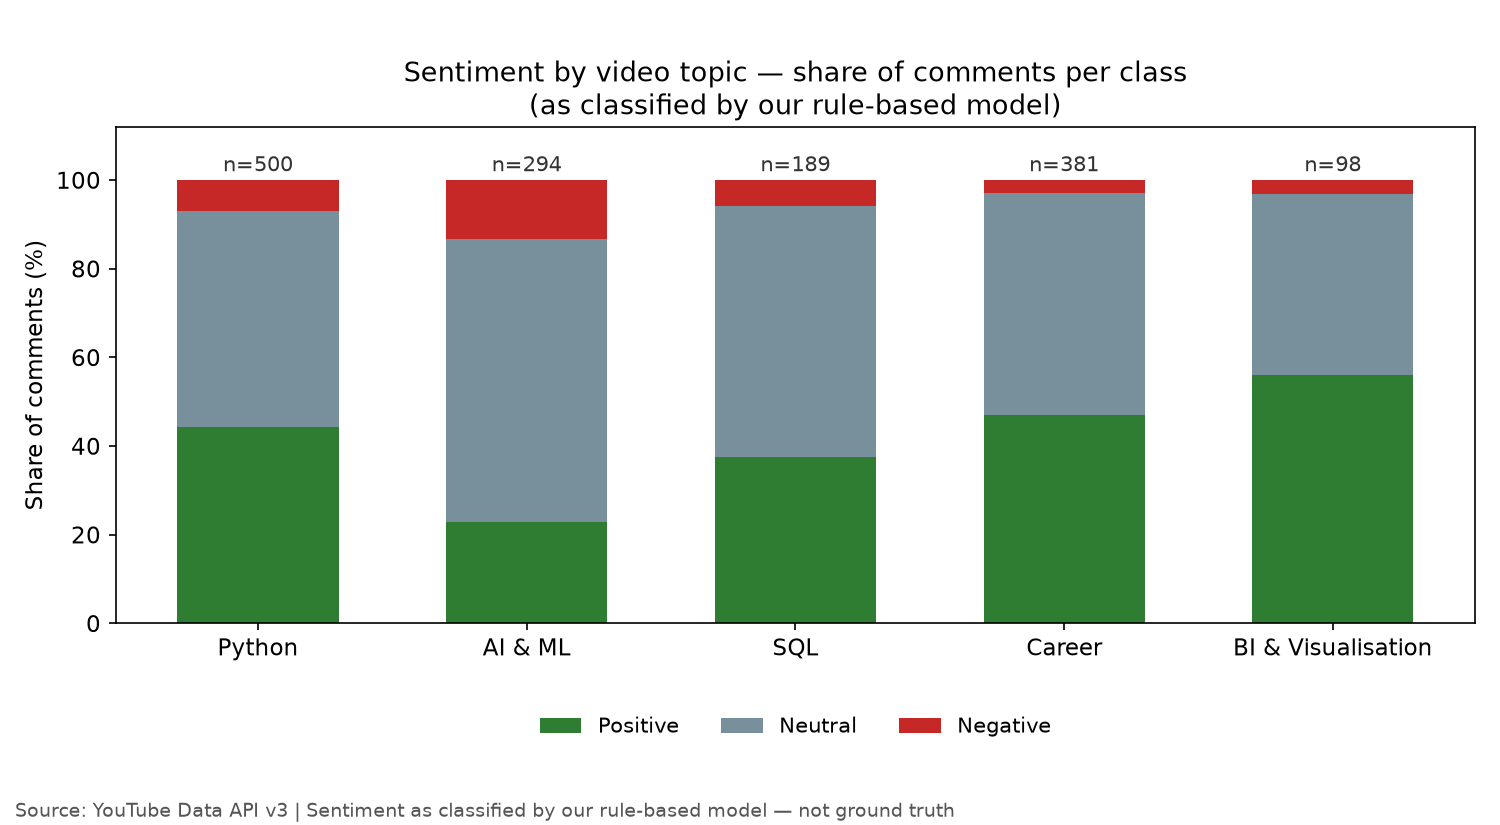

In [5]:
from make_charts import chart_01_sentiment_trend, chart_02_sentiment_by_topic
chart_01_sentiment_trend(comments)
chart_02_sentiment_by_topic(comments)
from IPython.display import Image, display
display(Image(str(CHARTS / "01_sentiment_trend.png")))
display(Image(str(CHARTS / "02_sentiment_by_topic.png")))

## Q2 — What are viewers actually talking about, and what are they complaining about?

Themes are fixed keyword lists (up to 2 per comment); a comment matching none is `other`. Theme shares sum to over 100% because a comment can carry 2 themes. The top words/bigrams are the check on what the fixed lists missed.

In [6]:
exploded = comments.assign(theme=comments["themes"].str.split(";")).explode("theme")
theme_table = pd.DataFrame({
    "count": exploded["theme"].value_counts(),
    "share_pct": exploded["theme"].value_counts(normalize=True) * 100,
})
for label in ("positive", "neutral", "negative"):
    theme_table[label] = exploded[exploded["sentiment"] == label]["theme"].value_counts()
theme_table = theme_table.fillna(0).astype({"count": int})
theme_table.round(1)

,count,share_pct,positive,neutral,negative
theme,,,,,
other,862,53.7,190,618,54.0
praise,329,20.5,300,16,13.0
career,144,9.0,58,78,8.0
tutorial_quality,116,7.2,82,20,14.0
price_cost,38,2.4,18,17,3.0
questions,33,2.1,7,22,4.0
audio_video,29,1.8,18,8,3.0
humor,27,1.7,17,7,3.0
criticism,21,1.3,9,2,10.0


In [7]:
for label in ("positive", "negative", "neutral"):
    texts = comments[comments["sentiment"] == label]["text"].tolist()
    print(f"--- top words ({label}, n={len(texts)}) ---")
    print(top_words(texts, 10))
    print(f"--- top bigrams ({label}) ---")
    print(top_bigrams(texts, 10))
    print()

--- top words (positive, n=594) ---
[('data', 139), ('analytics', 97), ('google', 92), ('thank', 61), ('good', 54), ("i'm", 47), ('better', 43), ('best', 41), ('great', 41), ('thanks', 39)]
--- top bigrams (positive) ---
[('data analytics', 87), ('google data', 78), ('easy follow', 22), ('enjoyed every', 21), ('every second', 21), ('clear easy', 20), ('deserves recognition', 17), ('appreciate effort', 16), ('good luck', 16), ('helped understand', 15)]

--- top words (negative, n=99) ---
[('ai', 25), ('good', 15), ('data', 10), ('hidden', 10), ('human', 10), ('time', 10), ('understand', 10), ('every', 9), ('humans', 9), ("it's", 9)]
--- top bigrams (negative) ---
[('expect good', 6), ('data analytics', 5), ('hidden layer', 4), ('layer neurons', 4), ('answers internet', 3), ('doesn t', 3), ('hidden layers', 3), ('high value', 3), ('made expect', 3), ('never learnt', 3)]

--- top words (neutral, n=769) ---
[('data', 119), ('analytics', 94), ('google', 90), ('ai', 39), ("i'm", 34), ('pleas

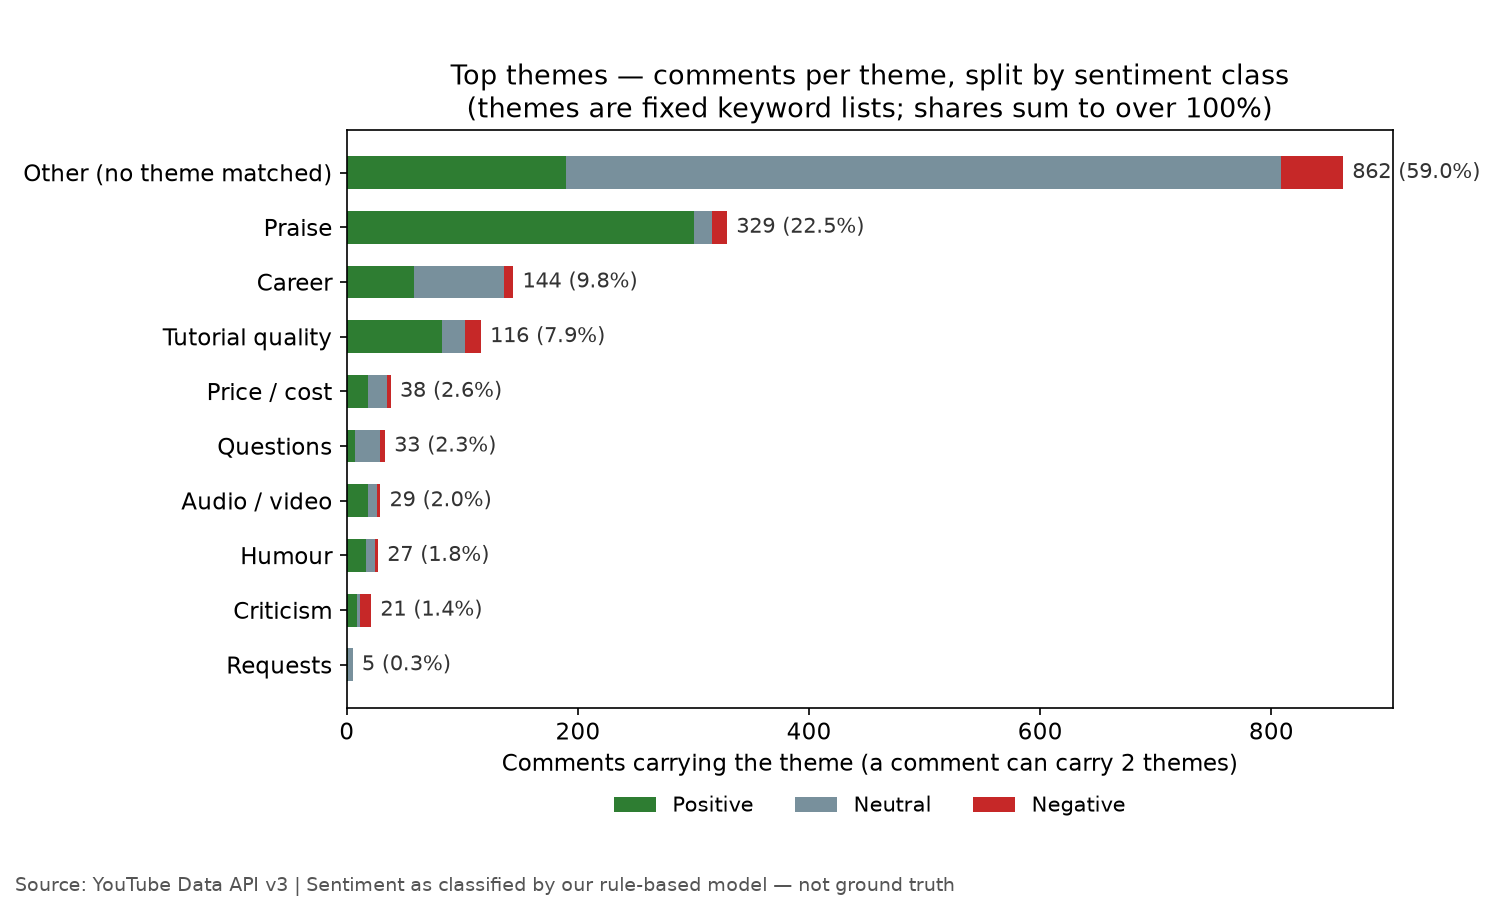

In [8]:
from make_charts import chart_03_top_themes
chart_03_top_themes(comments)
from IPython.display import Image, display
display(Image(str(CHARTS / "03_top_themes.png")))

## Q3 — How far can the sentiment model be trusted?

120 comments, stratified 40 per predicted class (seed 42), labelled blind by a human using a fixed rubric. The confusion matrix and per-class precision/recall/F1 below are the evidence — there is no pass threshold; the honest measurement is the deliverable.

In [9]:
merged = comments.merge(labels, on="comment_id", how="inner")
evaluation = evaluate_predictions(
    merged["sentiment"].tolist(), merged["human_label"].tolist()
)
print(f"n={evaluation['n']}  accuracy={evaluation['accuracy']:.4f}  "
      f"macro-F1={evaluation['macro_f1']:.4f}")
pd.DataFrame(evaluation["confusion"]).T.rename_axis("human \\ predicted")

n=120  accuracy=0.6167  macro-F1=0.6131


,positive,neutral,negative
human \ predicted,,,
positive,30,12,10
neutral,7,25,11
negative,3,3,19


In [10]:
for label, metrics in evaluation["per_class"].items():
    print(f"{label:>9}: P={metrics['precision']:.3f}  "
          f"R={metrics['recall']:.3f}  F1={metrics['f1']:.3f}  "
          f"(support {metrics['support']})")
print()
print("Biggest error cells (human -> predicted):")
print("  true positive  -> predicted negative:",
      int(((merged['human_label'] == 'positive') & (merged['sentiment'] == 'negative')).sum()))
print("  true neutral   -> predicted negative:",
      int(((merged['human_label'] == 'neutral') & (merged['sentiment'] == 'negative')).sum()))
print("  true positive  -> predicted neutral:",
      int(((merged['human_label'] == 'positive') & (merged['sentiment'] == 'neutral')).sum()))

 positive: P=0.750  R=0.577  F1=0.652  (support 52)
  neutral: P=0.625  R=0.581  F1=0.602  (support 43)
 negative: P=0.475  R=0.760  F1=0.585  (support 25)

Biggest error cells (human -> predicted):
  true positive  -> predicted negative: 10
  true neutral   -> predicted negative: 11
  true positive  -> predicted neutral: 12


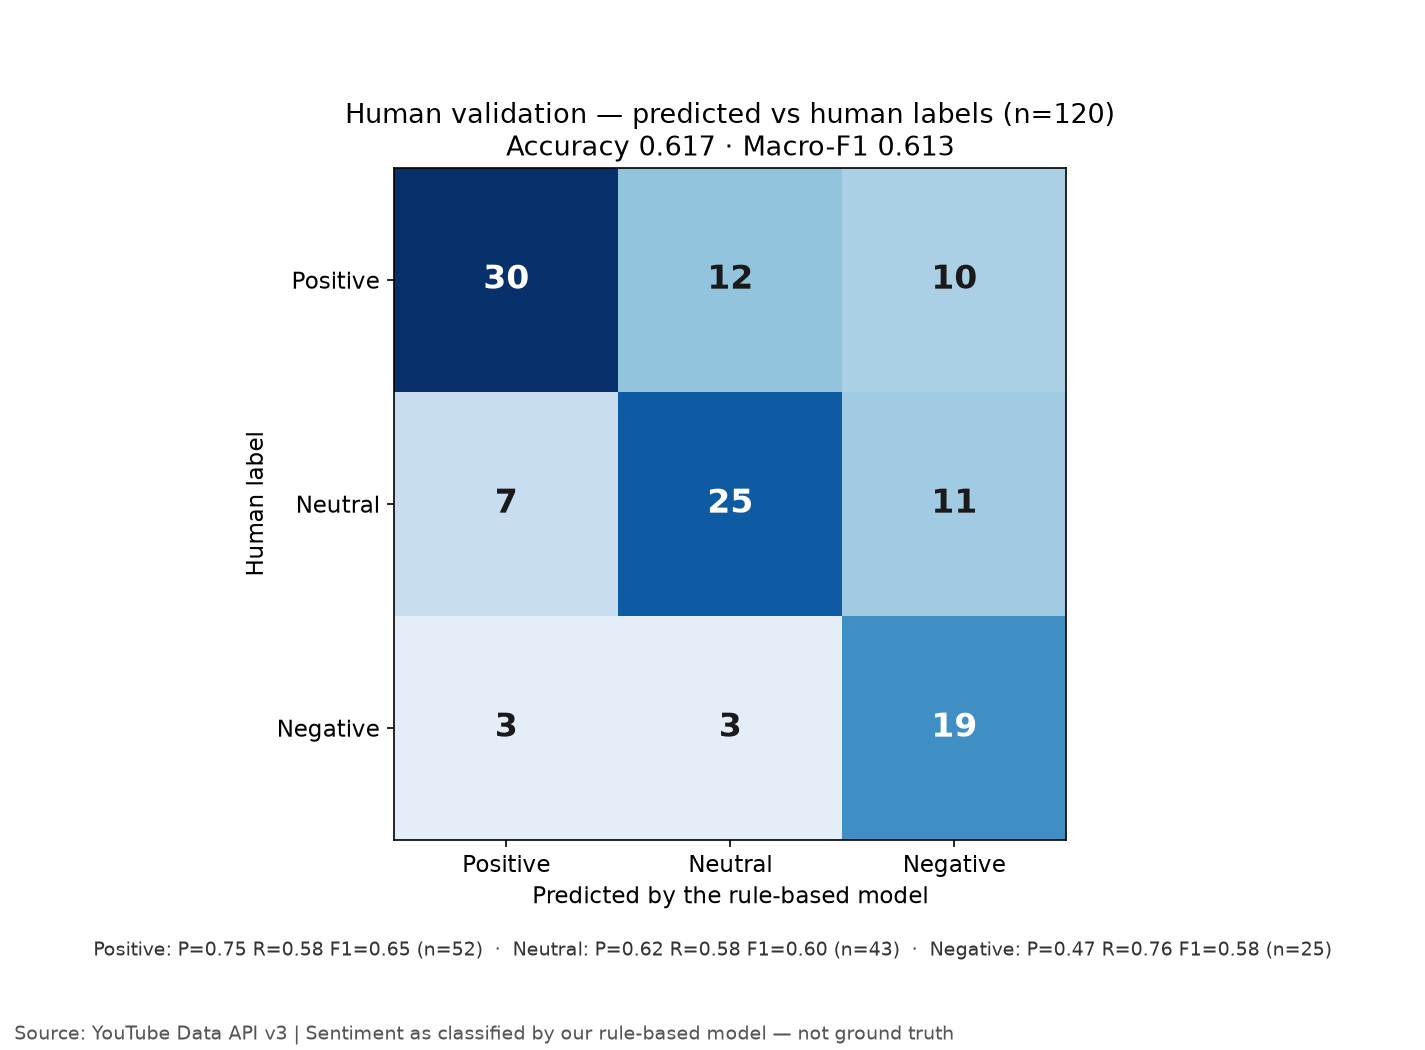

In [11]:
from make_charts import chart_04_validation_confusion
chart_04_validation_confusion(comments)
from IPython.display import Image, display
display(Image(str(CHARTS / "04_validation_confusion.png")))

## Limitations

- **Sentiment is a model output, not ground truth.** The rule-based lexicon scores 0.617 accuracy / 0.613 macro-F1 against 120 human labels — a modest baseline, better than chance (0.33) but far from reliable. Negative precision is only 0.48: the model over-predicts negative.
- **55.3% of comments matched no lexicon word** and are neutral by default, not by meaning — the neutral share is inflated by no-signal comments.
- **59.0% of comments matched no theme** (`other`) — the fixed theme lists missed the large Google Data Analytics course-cohort check-in pattern; the top bigrams (`google data`, `data analytics`) show it. Reported, not re-tuned.
- No sarcasm/irony detection; no context; no slang coverage beyond the authored lists; short comments usually score neutral by default.
- Latin-script non-English (e.g. Spanish) is not filtered by the non-Latin heuristic and mostly scores neutral.
- The API has no date filter: the 12-month window is applied after fetching, newest-first, up to 3 pages per video — so the window is filled unevenly across videos and the monthly trend partly reflects the changing video mix.
- Top-level comments only; replies are not fetched. Corpus: 12 high-comment-volume videos — findings describe these videos' comments, nothing broader.
- The lexicon was authored before seeing the comments and was not tuned after seeing validation results.